In [13]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time

In [7]:
device = torch.device("cpu")

In [8]:
words = open('names.txt').read().splitlines()
chars = sorted(list(set(''.join(words))))
stoio = {s:i+1 for i,s in enumerate(chars)}
stoio['.'] = 0
itos = {i:s for s, i in stoio.items()}

In [9]:
block_size = 8

def build_dataset(words):
    X = []
    Y = []
    for word in words:
        context = [0] * block_size
        for ch in word + '.':
            ix = stoio[ch]
            X.append(context)
            Y.append(ix)

            context = context[1:] + [ix]
    return torch.tensor(X), torch.tensor(Y)

import random
random.shuffle(words)

n1 = int(.8 * len(words))
n2 = int(.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

In [10]:
n_hidden = 300
n_emb = 100
n_vocab = 27

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((n_vocab, n_emb), generator=g)

W1 = torch.randn((n_emb * block_size, n_hidden), generator=g) * (5/3) / (n_emb * block_size) ** .5

W2 = torch.randn((n_hidden, n_vocab)) * .01
b2 = torch.randn(n_vocab, generator=g) * 0

bngain = torch.ones(1, n_hidden)
bnbias = torch.zeros(1, n_hidden)

bnmean = torch.zeros(1, n_hidden)
bnstd = torch.ones(1, n_hidden)

Xtr, Ytr, Xdev, Ydev, Xte, Yte, C, W1, W2, b2, bngain, bnbias = [
    p.to(device)
    for p in [Xtr, Ytr, Xdev, Ydev, Xte, Yte, C, W1, W2, b2, bngain, bnbias]
]

params = [W1, W2, b2, C, bngain, bnbias]

for p in params:
    p.requires_grad = True

In [11]:
lossi = []

In [12]:
max_steps = 100000
batch_size = 50
t = time.perf_counter()
for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), device=device)
    emb = C[Xtr[ix]]
    hpreact = emb.view(-1, n_emb * block_size) @ W1
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact -bnmeani) / bnstdi + bnbias

    with torch.no_grad():
        bnmean = bnmean * .999 + bnmeani * .001
        bnstd = bnstd * .999 + bnstdi * .001

    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    lossi.append(loss.item())

    for p in params:
        p.grad = None
    loss.backward()
    lr = .1 if i < max_steps / 2 else .01
    for p in params:
        p.data += -lr * p.grad

    if i % int(max_steps / 20) == 0:
        print(f'step {i}/{max_steps}: {loss.item():.4f}')

t = time.perf_counter() - t

step 0/100000: 3.3130
step 5000/100000: 2.1365
step 10000/100000: 2.2159
step 15000/100000: 2.1780
step 20000/100000: 2.3626
step 25000/100000: 2.1300
step 30000/100000: 1.8309
step 35000/100000: 2.2156
step 40000/100000: 1.9092
step 45000/100000: 2.1752
step 50000/100000: 2.0778
step 55000/100000: 1.5193
step 60000/100000: 1.7448
step 65000/100000: 1.8089
step 70000/100000: 1.8106
step 75000/100000: 1.9294
step 80000/100000: 2.0558
step 85000/100000: 2.0808
step 90000/100000: 2.0921
step 95000/100000: 1.8222


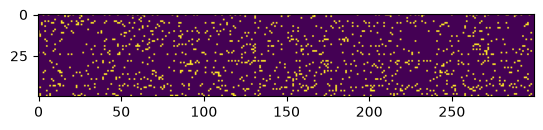

In [14]:
plt.imshow(h.abs() > .99, )

In [15]:
with torch.no_grad():
    emb = C[Xtr]
    hpreact = emb.view(-1, n_emb * block_size) @ W1
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)

print(bnmean, bnstd)

tensor([[ 2.1631,  1.9479,  3.1087, -1.6722, -3.5202,  3.6284,  1.0279, -2.4758,
         -0.5563, -0.2113, -0.7059,  0.0831,  1.4692, -1.0041,  1.7795, -1.6315,
         -1.4101, -1.9622, -0.3790,  0.1108, -0.9413, -0.8223,  0.3321, -0.8880,
         -0.2727,  3.1011, -3.2915, -2.5377, -1.5820, -3.1651, -0.4571, -0.2127,
         -0.5907,  4.7057, -2.8539, -1.1176, -1.2576,  1.9524,  0.7149,  2.0235,
          0.9296, -3.4600,  1.9462,  0.1724, -3.0042, -3.1995,  2.2995,  1.8784,
         -1.7970,  2.3032,  0.1978, -1.3718, -0.5150, -0.4503,  0.9410,  1.3850,
         -1.5685, -1.1611,  3.2798, -1.9442,  0.4683, -2.7072, -3.7695,  0.5451,
          2.4237,  1.0860,  0.6312, -0.2324, -0.7940, -2.8941,  0.1033,  1.3331,
         -1.9702, -0.1662,  0.8061,  3.0581,  1.8122, -0.1185, -1.5735,  1.1055,
          1.6236, -0.4768,  6.0501, -0.1157, -0.1096, -3.6016,  0.4055, -3.3279,
         -0.6998, -1.0509, -0.8163, -1.4270, -1.6794, -0.9121,  2.1896, -1.8807,
         -6.3674, -1.1623, -

In [16]:
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'dev': (Xdev, Ydev),
        'test': (Xte, Yte)
    }[split]
    emb = C[x]
    hpreact = (emb.view(-1, block_size * n_emb) @ W1)
    hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    return loss.item()

print(f'{t:.2f}s')
print(split_loss('train'))
print(split_loss('dev'))

126.59s
1.7882773876190186
1.999395728111267


With scaling
52.94s
1.9847157001495361
2.1042821407318115

Without scaling
53.38s
2.0430736541748047
2.1773693561553955

with kaiming
60.37s
2.015230178833008
2.0852794647216797

with bn
85.69s
2.0100855827331543
2.07128643989563

In [17]:
((hpreact) / hpreact.std()).std()

tensor(1.)

In [22]:
for _ in range(10):
    x = torch.tensor([0, 0, 0, 0, 0, 0, 0, 0])
    w = ''
    while True:
        e = C[x].view(-1, n_emb * block_size)
        hpreact = e @ W1
        hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
        h = torch.tanh(hpreact)
        logits = h @ W2 + b2
        p = logits.exp()
        p /= p.sum(1, keepdim=True)
        y = torch.multinomial(p, 1).item()
        if y == 0:
            break
        w += itos[y]
        x = torch.cat((x[1:], torch.tensor([y])), dim=0)
    print('' + w)

marson
avran
nickayla
clarave
meleaha
chiros
nashti
mathiyci
niya
aunisto


In [23]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True, scale=False, kaiming=False):
        self.w = torch.randn((fan_in, fan_out))
        if scale:
            self.w *= .2
        if kaiming:
            self.w *= (5/3) / (fan_in) ** .5
        self.b = torch.randn(fan_out) if bias else None

    def __call__(self, x):
        out = x @ self.w
        if self.b != None:
            out = out + self.b
        return out

    def parameters(self):
        params = [self.w]
        if self.b != None:
            params.append(self.b)
        return params


class Emb:
    def __init__(self, dim, fan_out):
        self.fan_out = fan_out
        self.emb = torch.randn(dim)

    def parameters(self):
        return [self.emb]

    def __call__(self, x):
        return self.emb[x]


class FlattenConsecutive:
    def __init__(self, n):
        self.n = n

    def __call__(self, x: torch.Tensor):
        B, T, C = x.shape
        x = x.view(B, T // self.n, C * self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        return x

    def parameters(self):
        return []


class Tanh:
    def __call__(self, x):
        return torch.tanh(x)

    def parameters(self):
        return []


class BatchNorm1d:
    def __init__(self, fan_in, momentum=.01):
        self.gain = torch.ones(fan_in)
        self.bias = torch.zeros(fan_in)
        self.running_mean = torch.zeros(fan_in)
        self.running_var = torch.ones(fan_in)
        self.momentum = momentum

    def __call__(self, x: torch.Tensor):
        if x.ndim == 2:
            dim = 0
        else:
            dim = (0, 1)
        if self.training:
            xmean = x.mean(dim, keepdim=True)
            xvar = x.var(dim, keepdim=True)

            with torch.no_grad():
                self.running_mean = self.running_mean * (1-self.momentum) + xmean * self.momentum
                self.running_var = self.running_var * (1-self.momentum) + xvar * self.momentum
        else:
            xmean = self.running_mean
            xvar = self.running_var
        return self.gain * ((x - xmean) / torch.sqrt(xvar + 1e-9) ) + self.bias

    def parameters(self):
        return [self.gain, self.bias]


class Container:
    def __init__(self, layers):
        self.layers = layers

        for p in self.parameters():
            p.requires_grad = True

    def __call__(self, x):
        out = x
        for l in self.layers:
            out = l(out)

        return out

    def parameters(self) -> list[torch.Tensor]:
        out = []
        for l in self.layers:
            out = out + l.parameters()
        return out


    def zero_grad(self):
        for p in self.parameters():
            p.grad = None

In [24]:
n_hidden = 256
n_emb = 48
n_vocab = 27

model = Container([
    Emb((n_vocab, n_emb), n_emb * block_size),
    FlattenConsecutive(2), Linear(n_emb * 2, n_hidden, kaiming=True), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, kaiming=True), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, kaiming=True), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_vocab, scale=True)
])

print(sum(p.nelement() for p in model.parameters()))

297259


6.290175437927246
2.196547269821167
1.7831215858459473
2.1900417804718018
1.7071869373321533
1.8790826797485352
2.262984275817871
2.0997540950775146
1.9850789308547974
2.086883544921875
1.7553126811981201
1.6899101734161377
1.5150686502456665
1.700934886932373
1.5697743892669678
1.5888614654541016
1.6809161901474
1.8257585763931274
1.9935694932937622
1.9807695150375366


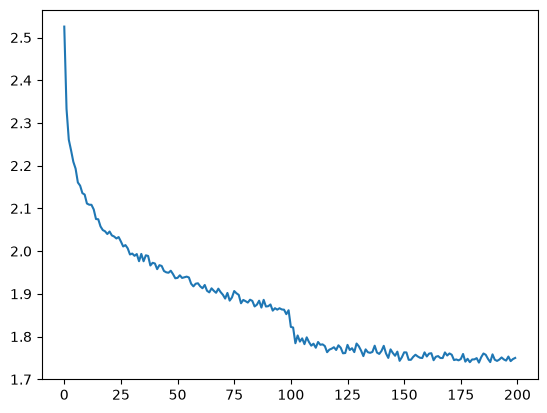

In [25]:
for p in model.layers:
    p.training = True

lossi = []
max_steps = 200000
for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (32, ))

    logits = model(Xtr[ix])
    loss = F.cross_entropy(logits, Ytr[ix])

    model.zero_grad()
    loss.backward()

    for p in model.parameters():
        lr = .1 if i < max_steps/2 else .01
        if i > max_steps * .75:
            lr = .001
        p.data += -1 * p.grad * lr

    if i % 10000 == 0:
        print(loss.item())

    lossi.append(loss.item())
    # break

plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [26]:
for p in model.layers:
    p.training = False

logits = model(Xdev)
loss = F.cross_entropy(logits, Ydev)
print(loss.item())

1.9886294603347778


```
big net (10, 100): 2.1214065551757812
with kaiming: 2.1053993701934814
with batchnorm: 2.1008527278900146
with multistep lr: 2.095
with block size = 8: 2.0471999645233154
with block size = 8 (bn before thanh): 2.0335853099823
wavenet (68 hidden): 2.058053493499756
bigger wavenet (20, 100): 2.0047976970672607
bigger wavenet (24, 128)
```

In [27]:
for _ in range(10):
    x = torch.tensor([[0, 0, 0, 0, 0, 0, 0, stoio['s']]])
    w = ''
    while True:
        logits = model(x)
        p = F.softmax(logits, dim=1)
        y = torch.multinomial(p, 1).item()
        if y == 0:
            break
        w += itos[y]
        x = torch.cat((x[:, 1:], torch.tensor([[y]])), dim=1)
        # print(x)
        # break
    print('s' + w)

serino
shuelli
selyn
stonelly
suvi
simir
soji
sterlin
sylon
sriya


In [28]:
class FlattenConsecutive(torch.nn.Module):
    def __init__(self, n):
        super().__init__()
        self.n = n

    def forward(self, x):
        B, T, C = x.shape
        x = x.view(B, T // self.n, C * self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        return x

class BatchNormLastDim(torch.nn.Module):
    def __init__(self, fan_in):
        super().__init__()
        self.bn = torch.nn.BatchNorm1d(fan_in)

    def forward(self, x):
        shape = x.shape
        x = self.bn(x.view(-1, shape[-1]))
        return x.view(shape)

0.00% | 13.61s -> 3.37009
0.05% | 26.11s -> 2.02533
0.10% | 37.56s -> 2.33613
0.15% | 48.93s -> 2.00825
0.20% | 60.22s -> 1.46694
0.25% | 71.42s -> 1.91943
0.30% | 82.85s -> 2.34897
0.35% | 95.60s -> 1.69501
0.40% | 106.90s -> 1.69842
0.45% | 118.22s -> 1.52968
0.50% | 129.55s -> 2.14899
0.55% | 140.77s -> 1.62800
0.60% | 152.23s -> 1.83980
0.65% | 163.43s -> 2.14628
0.70% | 174.78s -> 1.66940
0.75% | 186.06s -> 2.01165
0.80% | 197.36s -> 2.09326
0.85% | 208.72s -> 1.65619
0.90% | 219.98s -> 1.80249
0.95% | 231.20s -> 1.55406


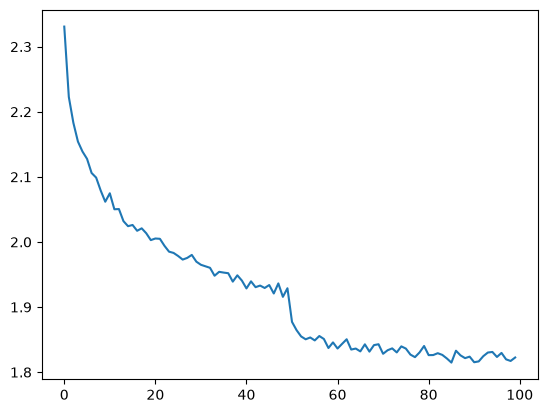

In [29]:
batch_size = 32
max_steps = 200000
n_hidden = 128
n_emb = 24

model = torch.nn.Sequential(
    torch.nn.Embedding(n_vocab, n_emb),
    FlattenConsecutive(2), torch.nn.Linear(
        2 * n_emb, n_hidden, bias=False), BatchNormLastDim(n_hidden), torch.nn.Tanh(),
    FlattenConsecutive(2), torch.nn.Linear(
        2 * n_hidden, n_hidden, bias=False), BatchNormLastDim(n_hidden), torch.nn.Tanh(),
    FlattenConsecutive(2), torch.nn.Linear(
        2 * n_hidden, n_hidden, bias=False), BatchNormLastDim(n_hidden), torch.nn.Tanh(),
    torch.nn.Linear(n_hidden, n_vocab)
)
optimizer = torch.optim.SGD(model.parameters(), lr=.1)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[int(max_steps*.50)], gamma=0.1)
model = model.to(device).train()

@torch.compile
def compute_loss(x, y):
    return F.cross_entropy(model(x), y)

lossi = []
t = time.perf_counter()
for step in range(max_steps):
    ix = torch.randint(Xtr.shape[0], (batch_size, ), device=Xtr.device)
    loss = compute_loss(Xtr[ix], Ytr[ix])

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()

    if step % (max_steps // 20) == 0:
        print(f'{step/max_steps:.2f}% | {time.perf_counter() - t:.2f}s -> {loss.item():.5f}')
    lossi.append(loss.detach())

plt.plot(torch.tensor(lossi).view(-1, (max_steps // 100)).mean(dim=1))

In [30]:
model.eval()
with torch.no_grad():
    logits = model(Xdev)
    loss = F.cross_entropy(logits, Ydev)
    print(loss.item())

1.997214913368225


In [31]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn((B, T, C))

head_size = 16
key = torch.nn.Linear(C, head_size, bias=False)
query = torch.nn.Linear(C, head_size, bias=False)
value = torch.nn.Linear(C, head_size)
k = key(x)
q = query(x)

wei = q @ k.transpose(-2, -1)

tril = torch.tril(torch.ones((T,T)))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

out = wei @ value(x)
out.shape

torch.Size([4, 8, 16])

In [32]:
k[0][0]

tensor([ 0.1260, -0.0932,  0.0556, -0.1119, -0.0859, -0.0314,  0.0825, -0.0175,
         0.1116,  0.0046,  0.0527,  0.0456, -0.1265, -0.1446,  0.0052,  0.0708],
       grad_fn=<SelectBackward0>)